# ALDH3B2 compliant receptor construction

This notebook constructs ALDH3B2 receptor states **only** from:

- A **user-supplied OpenFold prediction** for UniProt **P48448** (ALDH3B2), provided as a local PDB/CIF file. OpenFold has no public per-protein hosted API or precomputed database the way AlphaFold DB does, so the structure is uploaded/pointed to locally rather than fetched over the network, and its sequence is independently cross-checked against the canonical UniProt entry.
- Experimental wwPDB entries **5FHZ** and **8DR9** (PDB archive coordinate data: CC0; cite the original structures).

It deliberately does **not** read, align to, copy coordinates from, define a grid from, or dock against any AlphaFold DB or AlphaFold Server output. Keep all AlphaFold-derived files outside this notebook and use them only in a separate qualitative-validation analysis if you want one.

> **Licensing note:** OpenFold's code is Apache 2.0, but depending on which weights you used to generate your structure (an OpenFold-trained checkpoint vs. converted AlphaFold2 parameters), different license terms may apply to the *weights* and therefore arguably to structures produced with them. This notebook does not adjudicate that for you -- fill in `OPENFOLD_MODEL_INFO` in the Configuration cell and confirm the terms that apply to your own output before distributing results.

## Outputs

- Source manifest with your OpenFold file's hash/provenance metadata, UniProt cross-check, template URLs/hashes and licences.
- Apo ALDH3B2 receptor from your OpenFold prediction.
- Independent NAD-transfer candidates from every usable 5FHZ/8DR9 chain.
- Donor ranking, pocket RMSD, sequence coverage, clash checks and donor-pose agreement.
- Preferred provisional holo model plus an explicit review gate if donor NAD poses disagree.
- Pocket pLDDT, and pocket PAE **only if you supplied an OpenFold PAE file** (never fabricated otherwise).
- Apo and holo-protein protonation at pH 7.4.
- Protonated apo PDB/PQR, protonated holo PDB with transferred NAD preserved, and apo PDBQT.
- Final homolog-analysis tables, provenance report and ZIP archive.

> **Important:** transferred NAD has coordinates but is not automatically force-field parameterised. The notebook does not claim protein-NAD ipTM/PAE because the OpenFold target is a protein monomer prediction and NAD is transferred after prediction. A cofactor-aware parameterisation/minimisation step is still required before quantitative docking or MD.


In [1]:
#@title 1. Install reproducible dependencies
!pip -q install \
    "biopython>=1.83" "pandas>=2.0" "numpy>=1.24" "matplotlib>=3.7" \
    "requests>=2.31" "pdb2pqr>=3.6" "gemmi==0.7.1" "meeko==0.7.1" \
    "rdkit>=2023.9" "py3Dmol>=2.0"

# NOTE: every package this notebook needs -- including gemmi/meeko/rdkit,
# which used to be re-installed halfway through the run -- is pinned and
# installed exactly once, here, in the first cell. Upgrading numpy/rdkit/
# gemmi mid-session (after they, or something linked against their C
# extensions, are already imported) is a well-known source of ABI
# mismatches and "worked the first time, breaks on retry" failures in
# Colab. If you ever need different pins, edit them here and then use
# Runtime > Restart runtime before re-running, rather than pip-upgrading
# mid-notebook.


In [2]:
#@title 2. Configuration
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, copy, hashlib, shutil, subprocess, textwrap, warnings, time, pickle
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio.PDB import MMCIFParser, PDBParser, PDBIO, Select, Superimposer, Chain
from Bio.Align import PairwiseAligner
from Bio.Data.IUPACData import protein_letters_3to1_extended as AA3

UNIPROT = "P48448"
TEMPLATES = ["5FHZ", "8DR9"]
MODEL_TAG = "OpenFold"   # used only in output filenames

# --- Co-folded holo (protein+NAD) target, chain identities ---
PROTEIN_CHAIN_ID = "A"
LIGAND_CHAIN_ID = "B"
LIGAND_CCD_CODE = "NAD"

# Leave any of these as None to be prompted with a Colab upload widget instead.
OPENFOLD_HOLO_STRUCTURE_PATH = None          # .cif/.pdb holo prediction
OPENFOLD_CONFIDENCE_PATH = None              # *_confidences_aggregated.json
OPENFOLD_EXPERIMENT_CONFIG_PATH = None       # experiment_config.json (optional)
OPENFOLD_QUERY_SET_PATH = None               # inference_query_set.json (optional)
OPENFOLD_MODEL_ARCH_CONFIG_PATH = None       # model_config.json (optional; checkpoint architecture, hashed only)

# Optional: a separate per-residue PAE file (JSON with "predicted_aligned_error"/
# "pae", or a pickled OpenFold output dict containing one). The aggregated
# confidence file above normally does NOT include a full PAE matrix, so this
# stays a separate opt-in. Leave as None to skip PAE analysis (not fabricated).
OPENFOLD_PAE_PATH = None

# Placeholders; overwritten from experiment_config.json / inference_query_set.json
# in cell 3 if those are supplied, so the provenance report reflects reality
# rather than hand-typed guesses.
OPENFOLD_MODEL_INFO = {
    "openfold_version_or_commit": "UNKNOWN - please fill in",
    "weights_used": "UNKNOWN - please fill in",
    "msa_database": "UNKNOWN - please fill in",
    "date_generated": "UNKNOWN - please fill in",
}

# --- Confidence gate applied to the co-folded protein+NAD prediction itself ---
MIN_ACCEPTABLE_IPTM = 0.75
MIN_ACCEPTABLE_CHAIN_PAIR_IPTM = 0.75
MAX_ACCEPTABLE_GPDE = 1.0
REJECT_IF_HAS_CLASH = True

PH = 7.4
POCKET_CUTOFF_A = 8.0
ROBUST_FIT_CUTOFF_A = 2.5
SEVERE_CLASH_A = 1.5
CLOSE_CONTACT_A = 2.0
DONOR_DISAGREEMENT_A = 3.0
MAKE_APO_PDBQT = True

# Set to None for objective automatic selection. To force a reviewed donor later,
# use a tuple such as ("5FHZ", "H") and rerun from the selection cell.
MANUAL_DONOR = None

ROOT = Path("/content/ROOTS_ALDH3B2") if Path("/content").exists() else Path.cwd()/"ROOTS_ALDH3B2"
SRC = ROOT/"docking_authorized_sources"
OUT = ROOT/"outputs"
REPORTS = ROOT/"reports"
for d in [SRC, OUT, REPORTS]: d.mkdir(parents=True, exist_ok=True)
print("Working directory:", ROOT)

Working directory: /content/ROOTS_ALDH3B2


## Source acquisition and audit

Unlike AlphaFold DB, OpenFold has no public per-protein REST API or hosted database of precomputed predictions -- it's inference code you run yourself, typically on your own compute. This notebook therefore takes your already-generated OpenFold structure (and, optionally, a PAE file) as a **local file** rather than fetching it from a network endpoint, and independently cross-checks its sequence against the canonical UniProt entry for ALDH3B2 as an identity QC step. Experimental 5FHZ/8DR9 NAD-donor templates are still pulled from the public wwPDB archive exactly as before, with SHA-256 hashes recorded for reproducibility.

In [3]:
#@title 3. Load your OpenFold3 holo (protein+NAD) prediction and download authorised homolog sources
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# --- Add configuration parameter for model_config.json ---
OPENFOLD_MODEL_ARCH_CONFIG_PATH = None

def _get_with_retries(url, timeout, attempts=3, backoff=2.0):
    last_exc = None
    for attempt in range(1, attempts + 1):
        try:
            response = requests.get(url, timeout=timeout)
            response.raise_for_status()
            return response
        except requests.RequestException as exc:
            last_exc = exc
            if attempt < attempts:
                print(f"  retrying {url} (attempt {attempt}/{attempts}) after error: {exc}")
                time.sleep(backoff * attempt)
    raise last_exc

def download(url, path, attempts=3):
    if path.exists() and path.stat().st_size > 0:
        print(f"  using cached file: {path}")
        return hashlib.sha256(path.read_bytes()).hexdigest()
    response = _get_with_retries(url, timeout=180, attempts=attempts)
    path.write_bytes(response.content)
    return hashlib.sha256(response.content).hexdigest()

def _resolve_local_path(configured_path, dest_name, prompt, allowed_suffixes, required=True):
    """Use a configured local path if set; otherwise prompt for a Colab
    upload. Returns the resolved Path under SRC, or None if not required
    and nothing was supplied."""
    if configured_path:
        p = Path(configured_path)
        assert p.exists(), f"Configured path does not exist: {p}"
    elif IN_COLAB:
        print(prompt)
        uploaded = colab_files.upload()
        if not uploaded:
            if required:
                raise RuntimeError(f"No file uploaded, and this input is required: {prompt}")
            return None
        name = next(iter(uploaded))
        p = SRC / f"_incoming_{name}"
        p.write_bytes(uploaded[name])
    else:
        if required:
            raise RuntimeError(               f"No path configured and this isn't running in Colab, so there's no "
                f"upload widget available. Set the corresponding OPENFOLD_* path in "
                f"the Configuration cell and rerun. ({prompt})"
            )
        return None

    assert p.suffix.lower() in allowed_suffixes, (
        f"Unrecognised file extension for {prompt}: {p.suffix} (expected one of {allowed_suffixes})"
    )
    dest = SRC / f"{dest_name}{p.suffix.lower()}"
    if p.resolve() != dest.resolve():
        shutil.copyfile(p, dest)
    return dest

retrieved = datetime.now(timezone.utc).isoformat()

# --- Required: the co-folded protein+NAD structure and its confidence file ---
target_structure_path = _resolve_local_path(
    OPENFOLD_HOLO_STRUCTURE_PATH, "openfold3_ALDH3B2_holo_NAD",
    "Upload your OpenFold3 holo (protein+NAD) structure (.cif or .pdb):",
    {".cif", ".mmcif", ".pdb", ".ent"}, required=True,
)
target_structure_hash = hashlib.sha256(target_structure_path.read_bytes()).hexdigest()
print("Holo structure:", target_structure_path, "sha256:", target_structure_hash)

confidence_path = _resolve_local_path(
    OPENFOLD_CONFIDENCE_PATH, "openfold3_ALDH3B2_confidences_aggregated",
    "Upload the matching *_confidences_aggregated.json:",
    {".json"}, required=True,
)
confidence = json.loads(confidence_path.read_text())

# --- Optional: a separate per-residue PAE file. The aggregated confidence
#     file above is summary-only (avg_plddt/gpde/iptm/... scalars) and does
#     NOT carry a full PAE matrix, even though the checkpoint's own
#     model_config.json shows a PAE head is enabled -- so this stays a
#     distinct, opt-in upload rather than something inferred automatically. ---
openfold_pae_path = None
if OPENFOLD_PAE_PATH:
    p = Path(OPENFOLD_PAE_PATH)
    assert p.exists(), f"OPENFOLD_PAE_PATH does not exist: {p}"
    openfold_pae_path = SRC / f"openfold3_ALDH3B2_pae{p.suffix.lower()}"
    if p.resolve() != openfold_pae_path.resolve():
        shutil.copyfile(p, openfold_pae_path)
    print("PAE file:", openfold_pae_path)
else:
    print("No OPENFOLD_PAE_PATH set - protein PAE analysis will be skipped later (not fabricated).")

# --- Optional but recommended: the run's config/query-set files, for
#     genuine provenance instead of hand-typed placeholders ---
experiment_config_path = _resolve_local_path(
    OPENFOLD_EXPERIMENT_CONFIG_PATH, "openfold3_experiment_config",
    "Upload experiment_config.json (optional -- press Cancel/skip to omit):",
    {".json"}, required=False,
)
query_set_path = _resolve_local_path(
    OPENFOLD_QUERY_SET_PATH, "openfold3_inference_query_set",
    "Upload inference_query_set.json (optional -- press Cancel/skip to omit):",
    {".json"}, required=False,
)

# --- Optional: the checkpoint's architecture/training config. This is
#     per-checkpoint, not per-run (no seed or date in it), so it's recorded
#     as a hashed reference file only -- nothing is parsed out of it into
#     OPENFOLD_MODEL_INFO. ---
model_arch_config_path = _resolve_local_path(
    OPENFOLD_MODEL_ARCH_CONFIG_PATH, "openfold3_model_config",
    "Upload model_config.json (optional -- press Cancel/skip to omit):",
    {".json"}, required=False,
)

# Pull real provenance out of the config files where we have them, rather
# than trusting the hand-filled OPENFOLD_MODEL_INFO placeholders.
if experiment_config_path:
    exp_cfg = json.loads(experiment_config_path.read_text())
    OPENFOLD_MODEL_INFO["weights_used"] = exp_cfg.get("inference_ckpt_name", OPENFOLD_MODEL_INFO.get("weights_used"))
    OPENFOLD_MODEL_INFO["inference_ckpt_path"] = exp_cfg.get("inference_ckpt_path")
    OPENFOLD_MODEL_INFO["msa_server_url"] = exp_cfg.get("msa_computation_settings", {}).get("server_url")
    OPENFOLD_MODEL_INFO["structure_format"] = exp_cfg.get("output_writer_settings", {}).get("structure_format")

query_protein_sequence = None
query_ligand_ccd_codes = []
if query_set_path:
    query_set = json.loads(query_set_path.read_text())
    OPENFOLD_MODEL_INFO["seeds"] = query_set.get("seeds")
    for query in query_set.get("queries", {}).values():
        for chain in query.get("chains", []):
            if chain.get("molecule_type") == "PROTEIN" and chain.get("sequence"):
                query_protein_sequence = chain["sequence"]
            if chain.get("molecule_type") == "LIGAND" and chain.get("ccd_codes"):
                query_ligand_ccd_codes.extend(chain["ccd_codes"])
            entry_chains = chain.get("template_entry_chain_ids")
            if entry_chains:
                OPENFOLD_MODEL_INFO["template_entry_chain_ids"] = entry_chains
    assert LIGAND_CCD_CODE in query_ligand_ccd_codes or not query_ligand_ccd_codes, (
        f"Configured LIGAND_CCD_CODE={LIGAND_CCD_CODE!r} not found in the query "
        f"set's ligand CCD codes {query_ligand_ccd_codes!r}; check PROTEIN_CHAIN_ID/"
        f"LIGAND_CHAIN_ID/LIGAND_CCD_CODE in the Configuration cell."
    )

# Flag if any TEMPLATES entry was also used as a folding template for this
# prediction -- recorded as provenance only; see cell 4's template_provenance
# for why this never biases the downstream 5FHZ/8DR9 comparison.
seen_by_model = set(t.upper() for t in OPENFOLD_MODEL_INFO.get("template_entry_chain_ids") or [])
templates_compromised = [
   t for t in TEMPLATES
    if any(entry.upper().startswith(t.lower() + "_") or entry.upper().startswith(t.upper() + "_")
           for entry in (OPENFOLD_MODEL_INFO.get("template_entry_chain_ids") or []))
]
if templates_compromised:
    print(f"NOTE: {templates_compromised} appear in this prediction's own folding "
          f"templates -- recorded as provenance in cell 4's template_provenance; "
          f"scoring in cells 6/7/13 treats all TEMPLATES identically regardless.")

# --- Confidence gate: don't silently treat a low-confidence or clashing
#     interface as a usable holo structure. ---
iptm = confidence.get("iptm")
chain_pair_iptm = (confidence.get("chain_pair_iptm") or {}).get(f"({PROTEIN_CHAIN_ID}, {LIGAND_CHAIN_ID})")
gpde = confidence.get("gpde")
has_clash = bool(confidence.get("has_clash"))

confidence_flags = []
if iptm is None or iptm < MIN_ACCEPTABLE_IPTM:
    confidence_flags.append(f"iptm={iptm} below MIN_ACCEPTABLE_IPTM={MIN_ACCEPTABLE_IPTM}")
if chain_pair_iptm is None or chain_pair_iptm < MIN_ACCEPTABLE_CHAIN_PAIR_IPTM:
    confidence_flags.append(f"chain_pair_iptm={chain_pair_iptm} below MIN_ACCEPTABLE_CHAIN_PAIR_IPTM={MIN_ACCEPTABLE_CHAIN_PAIR_IPTM}")
if gpde is None or gpde > MAX_ACCEPTABLE_GPDE:
    confidence_flags.append(f"gpde={gpde} above MAX_ACCEPTABLE_GPDE={MAX_ACCEPTABLE_GPDE}")
if REJECT_IF_HAS_CLASH and has_clash:
    confidence_flags.append("has_clash=True")

holo_review_required = bool(confidence_flags)
if holo_review_required:
    print("MANUAL REVIEW REQUIRED before treating this holo prediction as usable:")
    for f in confidence_flags:
        print("  -", f)
else:
    print(f"Confidence gate passed: iptm={iptm}, chain_pair_iptm={chain_pair_iptm}, "
          f"gpde={gpde}, has_clash={has_clash}")

# --- Independent sequence check against UniProt (never AlphaFold) ---
uniprot_fasta_url = f"https://rest.uniprot.org/uniprotkb/{UNIPROT}.fasta"
uniprot_fasta = _get_with_retries(uniprot_fasta_url, timeout=60).text
uniprot_canonical_sequence = "".join(
    line.strip() for line in uniprot_fasta.splitlines() if not line.startswith(">")
)
assert uniprot_canonical_sequence, f"Could not parse a sequence from UniProt for {UNIPROT}"
print(f"UniProt canonical sequence length for {UNIPROT}: {len(uniprot_canonical_sequence)}")
if query_protein_sequence:
    print("Query-set protein sequence matches UniProt canonical sequence:",
          query_protein_sequence == uniprot_canonical_sequence)

# --- Homolog templates for independent geometric comparison: RCSB (wwPDB)
#     only. Never AlphaFold DB or AlphaFold Server. ---
sources = {}
for pdb_id in TEMPLATES:
    sources[pdb_id] = {
        "url": f"https://files.rcsb.org/download/{pdb_id}.cif",
        "path": str(SRC/f"{pdb_id}.cif"),
        "license": "CC0 1.0 (PDB archive coordinate data)",
        "role": "experimental NAD-pose cross-check",
        "used_as_folding_template_by_this_prediction": pdb_id in templates_compromised,
    }
for key, item in sources.items():
    item["sha256"] = download(item["url"], Path(item["path"]))

manifest = {
    "retrieved_utc": retrieved,
    "target": "Homo sapiens ALDH3B2",
    "uniprot": UNIPROT,
    "target_source": "OpenFold3 co-folded protein+NAD prediction (user-supplied local files; no hosted AlphaFold API/database used anywhere)",
    "target_structure_file": str(target_structure_path),
    "target_structure_sha256": target_structure_hash,
    "confidence_file": str(confidence_path),
    "confidence_summary": confidence,
    "confidence_gate": {
        "min_acceptable_iptm": MIN_ACCEPTABLE_IPTM,
        "min_acceptable_chain_pair_iptm": MIN_ACCEPTABLE_CHAIN_PAIR_IPTM,
        "max_acceptable_gpde": MAX_ACCEPTABLE_GPDE,
        "reject_if_has_clash": REJECT_IF_HAS_CLASH,
        "flags": confidence_flags,
        "manual_review_required": holo_review_required,
    },
    "openfold_model_info": OPENFOLD_MODEL_INFO,
    "model_architecture_config_file": str(model_arch_config_path) if model_arch_config_path else None,
    "model_architecture_config_sha256": (
        hashlib.sha256(model_arch_config_path.read_bytes()).hexdigest() if model_arch_config_path else None
    ),
    "templates_also_used_as_folding_templates_by_this_prediction": templates_compromised,
    "uniprot_canonical_sequence_source": uniprot_fasta_url,
    "sources": sources,
    "excluded_source_policy": {
        "AlphaFold_Server_output": "not read or used anywhere in this workflow",
        "AlphaFold_DB_output": "not used anywhere in this workflow",
        "target_coordinates_from": "user-supplied OpenFold3 co-folded prediction only",
        "homolog_sources_from": "RCSB/wwPDB only",
    }
}
(REPORTS/"source_manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))

Upload your OpenFold3 holo (protein+NAD) structure (.cif or .pdb):


Saving ALDH3B2_openfold3_holo_NAD_seed_2746317213_sample_5_model.cif to ALDH3B2_openfold3_holo_NAD_seed_2746317213_sample_5_model (3).cif
Holo structure: /content/ROOTS_ALDH3B2/docking_authorized_sources/openfold3_ALDH3B2_holo_NAD.cif sha256: 899eb57bd7d599b40bbaafa7e5f914f48375479a80cbef62702b1b079cf302e9
Upload the matching *_confidences_aggregated.json:


Saving ALDH3B2_openfold3_holo_NAD_seed_2746317213_sample_5_confidences.json to ALDH3B2_openfold3_holo_NAD_seed_2746317213_sample_5_confidences.json
No OPENFOLD_PAE_PATH set - protein PAE analysis will be skipped later (not fabricated).
Upload experiment_config.json (optional -- press Cancel/skip to omit):


Saving experiment_config.json to experiment_config (3).json
Upload inference_query_set.json (optional -- press Cancel/skip to omit):


Saving inference_query_set.json to inference_query_set (3).json
Upload model_config.json (optional -- press Cancel/skip to omit):


Streaming output truncated to the last 5000 lines.
        14.007969856262207,
        10.655529022216797,
        5.919332504272461,
        9.592278480529785,
        6.886066436767578,
        10.596006393432617,
        13.85312271118164,
        13.897071838378906,
        13.035223007202148,
        12.749374389648438,
        13.192268371582031,
        11.364951133728027,
        14.922769546508789,
        12.551271438598633,
        15.556051254272461,
        13.457056999206543,
        11.77544116973877,
        13.249774932861328,
        12.659284591674805,
        10.731206893920898,
        11.158249855041504,
        12.084470748901367,
        9.964503288269043,
        9.318436622619629,
        10.305191040039062,
        12.055200576782227,
        9.61154556274414,
        9.769245147705078,
        9.57125473022461,
        7.835477352142334,
        6.072373390197754,
        7.533804893493652,
        8.947397232055664,
        9.45237922668457,
        9.13580

In [4]:
#@title 4. Verify target identity, sequence, structure integrity and confidence
import gemmi
from Bio.PDB.MMCIFParser import MMCIFParser, MMCIF2Dict

class SafeMMCIFParser(MMCIFParser):
    """A robust subclass of Bio.PDB.MMCIFParser that intercepts missing
    _atom_site.occupancy fields and safely defaults them to 1.00,
    preventing standard Biopython KeyError crashes with OpenFold3 outputs."""
    def get_structure(self, structure_id, filename):
        # Read dictionary first
        self._mmcif_dict = MMCIF2Dict(filename)
        # If occupancy column is missing, backfill with default 1.00
        if "_atom_site.occupancy" not in self._mmcif_dict:
            num_atoms = len(self._mmcif_dict.get("_atom_site.id", []))
            self._mmcif_dict["_atom_site.occupancy"] = ["1.00"] * num_atoms
        self._build_structure(structure_id)
        self._structure_builder.set_header(self._get_header())
        return self._structure_builder.get_structure()

cif_parser = SafeMMCIFParser(QUIET=True)
pdb_parser = PDBParser(QUIET=True)

def ensure_atom_site_occupancy(path):
    """OpenFold3's mmCIF writer omits the (technically mandatory)
    _atom_site.occupancy column, which crashes Biopython's strict
    MMCIFParser with KeyError('_atom_site.occupancy'). Reopen with gemmi's
    tolerant reader, fill any missing/zero occupancies with 1.00, and write
    a patched *copy* alongside the original -- the original file and its
    already-recorded SHA-256 in source_manifest.json are left untouched."""
    path = Path(path)
    if path.suffix.lower() not in {".cif", "..mmcif"}:
        return path  # PDB format always carries an occupancy column
    st = gemmi.read_structure(str(path))
    st.setup_entities()
    patched = False
    for model in st:
        for chain in model:
            for residue in chain:
                for atom in residue:
                    if atom.occ is None or atom.occ <= 0:
                        atom.occ = 1.00
                        patched = True
    if not patched:
        return path  # occupancy was already present; nothing to fix
    fixed_path = path.with_name(path.stem + "_occfix.cif")
    st.make_mmcif_document().write_file(str(fixed_path))
    print(f"NOTE: {path.name} was missing _atom_site.occupancy; wrote a "
          f"patched copy with occupancy=1.00 for parsing: {fixed_path.name}")
    return fixed_path

def parse_structure(path):
    if path.suffix.lower() in {".cif", ".mmcif"}:
        return cif_parser.get_structure("ALDH3B2_OpenFold", str(path))
    return pdb_parser.get_structure("ALDH3B2_OpenFold", str(path))

# Parse from a (possibly) occupancy-patched copy; target_structure_path
# itself, and its hash in source_manifest.json, stay exactly as loaded in cell 3.
target_structure_path_for_parsing = ensure_atom_site_occupancy(target_structure_path)
target_structure = parse_structure(target_structure_path_for_parsing)
target_model = target_structure[0]

assert PROTEIN_CHAIN_ID in target_model, f"Protein chain {PROTEIN_CHAIN_ID} not found in model"
target_chain = target_model[PROTEIN_CHAIN_ID]

def standard_residues(chain):
    return [r for r in chain if r.id[0] == " " and r.resname.title() in AA3 and "CA" in r]

def residue_sequence(residues):
    return "".join(AA3[r.resname.title()] for r in residues)

target_residues = standard_residues(target_chain)
target_sequence = residue_sequence(target_residues)
assert target_sequence == uniprot_canonical_sequence, (
    "The OpenFold structure's sequence does not match the canonical UniProt "
    f"sequence for {UNIPROT}. Double-check this is the right prediction/chain "
    "(and the right isoform) before continuing."
)

raw_bfactors = np.array([r["CA"].bfactor for r in target_residues])
if raw_bfactors.max() <= 1.5:
    print("B-factor column looks like a 0-1 scale; rescaling pLDDT to 0-100.")
    plddt = raw_bfactors * 100.0
else:
    plddt = raw_bfactors

template_provenance = {
    pdb_id: {
        "used_as_folding_template_by_this_prediction": pdb_id in templates_compromised,
        "note": ("Provenance only -- does not affect scoring, ranking, or "
                  "selection. Both templates run through the identical "
                  "pipeline and are reported side by side (cell 13)."),
    }
    for pdb_id in TEMPLATES
}

identity_qc = {
    "uniprot": UNIPROT,
    "target_source": "OpenFold3 co-folded protein+NAD prediction (user-supplied)",
    "protein_chain_id": PROTEIN_CHAIN_ID,
    "openfold_model_info": OPENFOLD_MODEL_INFO,
    "length": len(target_sequence),
    "sequence_matches_uniprot_canonical": True,
    "mean_CA_pLDDT": float(plddt.mean()),
    "min_CA_pLDDT": float(plddt.min()),
    "fraction_CA_pLDDT_ge_90": float((plddt >= 90).mean()),
    "cofold_confidence": {
        "iptm": confidence.get("iptm"),
        "chain_pair_iptm": (confidence.get("chain_pair_iptm") or {}).get(
            f"({PROTEIN_CHAIN_ID}, {LIGAND_CHAIN_ID})"),
        "gpde": confidence.get("gpde"),
        "has_clash": bool(confidence.get("has_clash")),
        "flags": confidence_flags,
        "manual_review_required": holo_review_required,
    },
    "template_provenance": template_provenance,
    "equal_treatment_policy": (
        "5FHZ and 8DR9 are treated as equally eligible, independently scored "
        "homolog sources throughout this notebook. Folding-template overlap "
        "is recorded in template_provenance above as provenance only."
    ),
}
(REPORTS/"target_identity_qc.json").write_text(json.dumps(identity_qc, indent=2))
identity_qc

/usr/local/lib/python3.13/dist-packages/Bio/PDB/MMCIFParser.py:245: PDBConstructionWarning: PDBConstructionWarning: Non-existing residue ID in chain 'B', residue '.'
  warnings.warn(


{'uniprot': 'P48448',
 'target_source': 'OpenFold3 co-folded protein+NAD prediction (user-supplied)',
 'protein_chain_id': 'A',
 'openfold_model_info': {'openfold_version_or_commit': 'UNKNOWN - please fill in',
  'weights_used': 'openfold3-p2-155k',
  'msa_database': 'UNKNOWN - please fill in',
  'date_generated': 'UNKNOWN - please fill in',
  'inference_ckpt_path': '/root/.openfold3/of3-p2-155k.pt',
  'msa_server_url': 'https://api.colabfold.com/',
  'structure_format': 'cif',
  'seeds': [42],
  'template_entry_chain_ids': ['4l1o_A',
   '8bb8_A',
   '4qgk_B',
   '1ad3_B',
   '5fhz_E',
   '6tgw_D',
   '5abm_A',
   '4wp7_A',
   '5l2o_B',
   '7qk8_B',
   '7yob_F',
   '6alj_A',
   '3iwk_F',
   '6tgw_B',
   '5a2d_B',
   '7mjc_A',
   '6k10_A',
   '6try_A',
   '4o5h_C',
   '5gtk_C']},
 'length': 385,
 'sequence_matches_uniprot_canonical': True,
 'mean_CA_pLDDT': 95.4992865038961,
 'min_CA_pLDDT': 53.247547,
 'fraction_CA_pLDDT_ge_90': 0.8961038961038961,
 'cofold_confidence': {'iptm': None,


## Sequence-guided pocket fitting

For every protein chain containing NAD, the workflow:

1. Globally aligns the target and homolog sequences.
2. Defines donor-pocket residues within 8 Å of that donor chain's NAD.
3. Fits matched pocket Cα atoms with iterative outlier removal at 2.5 Å.
4. Transfers only NAD into the independent AlphaFold DB target frame.
5. Measures pocket RMSD and target–NAD heavy-atom contacts.

The clash cutoffs are conservative screening heuristics, not force-field energies. All candidates are retained for auditability.

In [5]:
#@title 5. Define alignment, transfer and quality-control functions
def heavy_coords(residue):
    xyz = [a.coord for a in residue if (a.element or "").upper() != "H"]
    return np.asarray(xyz, dtype=float)

def sequence_pairs(target_res, homolog_res):
    ts, hs = residue_sequence(target_res), residue_sequence(homolog_res)
    aligner = PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -10
    aligner.extend_gap_score = -0.5
    aln = aligner.align(ts, hs)[0]
    pairs = []
    for (t0, t1), (h0, h1) in zip(aln.aligned[0], aln.aligned[1]):
        pairs.extend((t0+i, h0+i) for i in range(min(t1-t0, h1-h0)))
    return ts, hs, pairs

def robust_superposition(target_atoms, homolog_atoms, cutoff=2.5, max_iter=10):
    keep = np.arange(len(target_atoms))
    for _ in range(max_iter):
        sup = Superimposer()
        sup.set_atoms([target_atoms[i] for i in keep], [homolog_atoms[i] for i in keep])
        rot, tran = sup.rotran
        moved = np.array([a.coord @ rot + tran for a in homolog_atoms])
        fixed = np.array([a.coord for a in target_atoms])
        distances = np.linalg.norm(moved-fixed, axis=1)
        new_keep = np.where(distances <= cutoff)[0]
        if len(new_keep) < 8:
            new_keep = np.argsort(distances)[:min(8, len(distances))]
        if np.array_equal(new_keep, keep):
            break
        keep = new_keep
    return sup, keep, distances

def selected_nad(chain):
    nads = [r for r in chain if r.resname == "NAD"]
    if not nads:
        return None
    # Bio.PDB selects the highest-occupancy alternative location for disordered atoms.
    return max(nads, key=lambda r: sum((a.occupancy or 0.0) for a in r))

def transfer_and_score(template_id, chain):
    hres = standard_residues(chain)
    nad = selected_nad(chain)
    ts, hs, pairs = sequence_pairs(target_residues, hres)
    nad_xyz = heavy_coords(nad)
    homolog_pocket = {
        j for j, r in enumerate(hres)
        if np.min(np.linalg.norm(heavy_coords(r)[:,None,:]-nad_xyz[None,:,:], axis=2)) <= POCKET_CUTOFF_A
    }
    pocket_pairs = [(i,j) for i,j in pairs if j in homolog_pocket]
    if len(pocket_pairs) < 8:
        raise ValueError(f"Too few matched pocket residues: {template_id} chain {chain.id}")
    sup, kept, distances = robust_superposition(
        [target_residues[i]["CA"] for i,j in pocket_pairs],
        [hres[j]["CA"] for i,j in pocket_pairs],
        ROBUST_FIT_CUTOFF_A
    )
    moved_nad = copy.deepcopy(nad)
    moved_nad.detach_parent()
    moved_nad.id = ("H_NAD", 1, " ")
    sup.apply(list(moved_nad.get_atoms()))
    moved_xyz = heavy_coords(moved_nad)
    severe, close = [], []
    target_pocket_indices = set()
    for idx, residue in enumerate(target_residues):
        distances_all = np.linalg.norm(heavy_coords(residue)[:,None,:]-moved_xyz[None,:,:], axis=2)
        minimum = float(distances_all.min())
        if minimum <= POCKET_CUTOFF_A:
            target_pocket_indices.add(idx)
        if minimum < SEVERE_CLASH_A:
            severe.append(f"{residue.resname}{residue.id[1]}:{minimum:.2f}")
        if minimum < CLOSE_CONTACT_A:
            close.append(f"{residue.resname}{residue.id[1]}:{minimum:.2f}")
    row = {
        "template": template_id, "chain": chain.id,
        "sequence_identity": sum(ts[i] == hs[j] for i,j in pairs)/len(pairs),
        "target_coverage": len(pairs)/len(ts),
        "matched_pocket_pairs": len(pocket_pairs), "fit_pairs_after_trimming": len(kept),
        "pocket_CA_RMSD_A": float(sup.rms),
        "severe_clashes_lt_1p5A": len(severe), "contacts_lt_2p0A": len(close),
        "severe_clash_detail": ";".join(severe),
        "target_pocket_residues": len(target_pocket_indices),
        "target_pocket_mean_pLDDT": float(np.mean([plddt[i] for i in target_pocket_indices]))
    }
    return row, moved_nad, target_pocket_indices

/usr/local/lib/python3.13/dist-packages/Bio/PDB/StructureBuilder.py:100: PDBConstructionWarning: WARNING: Chain A is discontinuous at line 29489.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/PDB/StructureBuilder.py:100: PDBConstructionWarning: WARNING: Chain B is discontinuous at line 29555.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/PDB/StructureBuilder.py:100: PDBConstructionWarning: WARNING: Chain C is discontinuous at line 29621.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/PDB/StructureBuilder.py:100: PDBConstructionWarning: WARNING: Chain D is discontinuous at line 29687.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/PDB/StructureBuilder.py:100: PDBConstructionWarning: WARNING: Chain E is discontinuous at line 29753.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/PDB/StructureBuilder.py:100: PDBConstructionWarning: WARNING: Chain F is discontinuous at line 29797.
  warnings.warn(
/usr/local/lib/python3

,template,chain,sequence_identity,target_coverage,matched_pocket_pairs,fit_pairs_after_trimming,pocket_CA_RMSD_A,severe_clashes_lt_1p5A,contacts_lt_2p0A,severe_clash_detail,target_pocket_residues,target_pocket_mean_pLDDT,used_as_folding_template_by_this_prediction
0,5FHZ,D,0.2980,0.9065,56,45,0.6356,0,3,,56,97.6003,True
1,5FHZ,G,0.2870,0.8779,46,36,0.6375,0,1,,58,97.5734,True
2,5FHZ,E,0.2989,0.9039,63,53,0.6439,0,0,,67,97.6205,True
3,5FHZ,B,0.2754,0.8961,39,29,0.6805,0,1,,56,97.8471,True
4,5FHZ,C,0.2971,0.9091,46,36,0.6809,0,1,,53,97.8902,True
5,5FHZ,F,0.2800,0.8442,49,34,0.8078,0,1,,59,97.5609,True
6,5FHZ,H,0.2971,0.9091,47,38,0.5702,1,1,ARG110:0.78,51,97.9058,True
7,5FHZ,A,0.2980,0.9065,58,47,0.6854,1,2,PRO109:1.15,63,97.5985,True
8,8DR9,A,0.2622,0.9013,65,46,0.8216,0,0,,65,97.5444,False
9,8DR9,B,0.2651,0.9013,66,48,0.9075,0,0,,64,97.5232,False


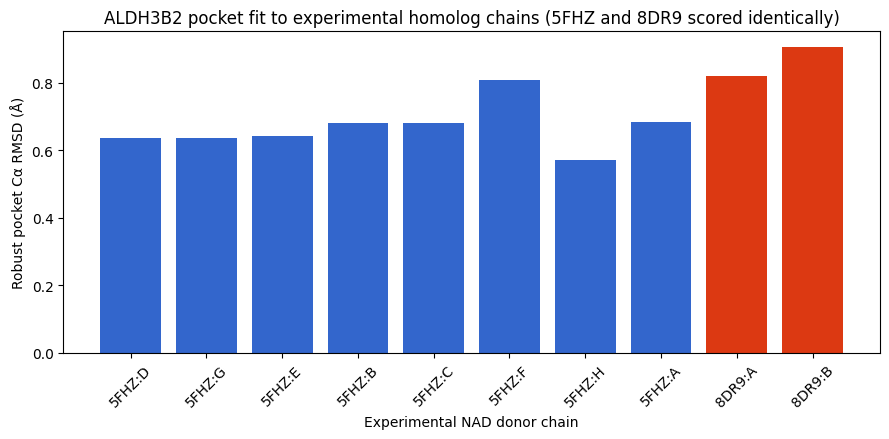

In [6]:
#@title 6. Analyse all NAD-bearing chains in 5FHZ and 8DR9
candidate_rows, candidate_nads, candidate_pockets = [], {}, {}
for pdb_id in TEMPLATES:
    homolog = cif_parser.get_structure(pdb_id, sources[pdb_id]["path"])[0]
    for chain in homolog:
        if selected_nad(chain) is None:
            continue
        row, moved_nad, pocket = transfer_and_score(pdb_id, chain)
        # Provenance-only annotation, carried from cell 4. Never read by any
        # sort/filter in this or later cells.
        row["used_as_folding_template_by_this_prediction"] = (
            template_provenance[pdb_id]["used_as_folding_template_by_this_prediction"]
        )
        key = (pdb_id, chain.id)
        candidate_rows.append(row)
        candidate_nads[key] = moved_nad
        candidate_pockets[key] = pocket

candidates = pd.DataFrame(candidate_rows)
candidates = candidates.sort_values(
    ["template", "severe_clashes_lt_1p5A", "pocket_CA_RMSD_A", "sequence_identity"],
    ascending=[True, True, True, False]
).reset_index(drop=True)
candidates.to_csv(REPORTS/"all_NAD_donor_candidates.csv", index=False)
display(candidates.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
labels = candidates["template"] + ":" + candidates["chain"]
colors = ["#3366cc" if x == "5FHZ" else "#dc3912" for x in candidates["template"]]
ax.bar(labels, candidates["pocket_CA_RMSD_A"], color=colors)
ax.set_ylabel("Robust pocket Cα RMSD (Å)")
ax.set_xlabel("Experimental NAD donor chain")
ax.set_title("ALDH3B2 pocket fit to experimental homolog chains (5FHZ and 8DR9 scored identically)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(REPORTS/"donor_pocket_rmsd.png", dpi=180)
plt.show()

In [7]:
#@title 7. Choose donor, compare independent NAD placements and enforce review gate
def best_row(group):
    return group.sort_values(
        ["severe_clashes_lt_1p5A", "pocket_CA_RMSD_A", "sequence_identity"],
        ascending=[True, True, False]
    ).iloc[0]

best_each = {pdb_id: best_row(candidates[candidates.template == pdb_id]) for pdb_id in TEMPLATES}

def nad_atom_dict(residue):
    return {a.name: np.asarray(a.coord) for a in residue if (a.element or "").upper() != "H"}

n1 = candidate_nads[("5FHZ", best_each["5FHZ"].chain)]
n2 = candidate_nads[("8DR9", best_each["8DR9"].chain)]
a1, a2 = nad_atom_dict(n1), nad_atom_dict(n2)
common = sorted(set(a1) & set(a2))
donor_pose_rmsd = float(np.sqrt(np.mean([np.sum((a1[k]-a2[k])**2) for k in common])))

if MANUAL_DONOR is not None:
    chosen_key = tuple(MANUAL_DONOR)
    assert chosen_key in candidate_nads, f"Manual donor {chosen_key} not found"
else:
    # Selection uses only the pocket-fit metrics from cell 6, computed
    # identically for every template. used_as_folding_template never enters
    # this sort, by design.
    eligible = candidates[candidates.severe_clashes_lt_1p5A == 0]
    if eligible.empty:
        raise RuntimeError("No transferred NAD pose passed the severe-clash gate")
    chosen = eligible.sort_values(
        ["pocket_CA_RMSD_A", "sequence_identity", "target_coverage"],
        ascending=[True, False, False]
    ).iloc[0]
    chosen_key = (chosen.template, chosen.chain)

review_required = donor_pose_rmsd > DONOR_DISAGREEMENT_A
selection = {
    "best_5FHZ_chain": best_each["5FHZ"].chain,
    "best_8DR9_chain": best_each["8DR9"].chain,
    "NAD_pose_RMSD_between_best_donors_A": donor_pose_rmsd,
    "disagreement_threshold_A": DONOR_DISAGREEMENT_A,
    "review_required": review_required,
    "preferred_provisional_donor": {"template": chosen_key[0], "chain": chosen_key[1]},
    "selection_rule": ("zero severe clashes, then lowest robust pocket C-alpha RMSD, "
                        "then higher sequence identity and coverage -- identical rule "
                        "applied to both templates"),
    "template_provenance": template_provenance,
    "interpretation": (
        "Independent donor NAD poses disagree; keep both receptor states and "
        "visually review before declaring a definitive holo receptor."
        if review_required else
        "Independent donor placements agree within the configured threshold."
    )
}
(REPORTS/"donor_selection.json").write_text(json.dumps(selection, indent=2))
selection

{'best_5FHZ_chain': 'D',
 'best_8DR9_chain': 'A',
 'NAD_pose_RMSD_between_best_donors_A': 4.894031047821045,
 'disagreement_threshold_A': 3.0,
 'review_required': True,
 'preferred_provisional_donor': {'template': '5FHZ', 'chain': 'D'},
 'selection_rule': 'zero severe clashes, then lowest robust pocket C-alpha RMSD, then higher sequence identity and coverage -- identical rule applied to both templates',
 'template_provenance': {'5FHZ': {'used_as_folding_template_by_this_prediction': True,
   'note': 'Provenance only -- does not affect scoring, ranking, or selection. Both templates run through the identical pipeline and are reported side by side (cell 13).'},
  '8DR9': {'used_as_folding_template_by_this_prediction': False,
   'note': 'Provenance only -- does not affect scoring, ranking, or selection. Both templates run through the identical pipeline and are reported side by side (cell 13).'}},
 'interpretation': 'Independent donor NAD poses disagree; keep both receptor states and visual

**Review gate:** A large difference between the 5FHZ-derived and 8DR9-derived NAD positions is scientifically meaningful. It may represent different ALDH/NAD conformations rather than a software failure. The notebook therefore exports both candidate states and labels the automatically preferred one *provisional* whenever the donor-pose RMSD exceeds the configured threshold.

In [8]:
#@title 8. Export apo, both best-donor holo candidates and preferred provisional holo
class ProteinOnly(Select):
    def accept_residue(self, residue):
        return int(residue.id[0] == " ")

def write_pdb(structure, path, remarks=None, selector=None):
    io = PDBIO()
    io.set_structure(structure)
    tmp = Path(str(path)+".tmp")
    io.save(str(tmp), selector or Select())
    header = "".join(f"REMARK 999 {line}\n" for line in (remarks or []))
    Path(path).write_text(header + tmp.read_text())
    tmp.unlink()

def make_holo(nad_residue):
    s = copy.deepcopy(target_structure)
    model = s[0]
    if "B" in model:
        model.detach_child("B")
    cofactor_chain = Chain.Chain("B")
    nad = copy.deepcopy(nad_residue)
    nad.detach_parent()
    nad.id = ("H_NAD", 1, " ")
    cofactor_chain.add(nad)
    model.add(cofactor_chain)
    return s

apo_path = OUT/f"ALDH3B2_{MODEL_TAG}_apo.pdb"
base_remarks = [
    f"SOURCE Target coordinates from a user-supplied OpenFold prediction for UniProt {UNIPROT} (ALDH3B2).",
    f"OpenFold model info: {OPENFOLD_MODEL_INFO}",
    "Sequence cross-checked against the canonical UniProt entry; see target_identity_qc.json.",
    "NOT DERIVED FROM ALPHAFOLD DB OR ALPHAFOLD SERVER OUTPUT.",
    "MODIFIED BY FORMAT CONVERSION AND/OR DOWNSTREAM PREPARATION; SEE source_manifest.json."
]
write_pdb(target_structure, apo_path, base_remarks, ProteinOnly())

holo_paths = {}
for donor_id in TEMPLATES:
    row = best_each[donor_id]
    key = (donor_id, row.chain)
    path = OUT/f"ALDH3B2_{MODEL_TAG}_holo_NAD_from_{donor_id}_chain_{row.chain}.pdb"
    remarks = base_remarks + [
        f"NAD COORDINATES TRANSFERRED FROM EXPERIMENTAL PDB {donor_id} CHAIN {row.chain} BY SEQUENCE-GUIDED POCKET SUPERPOSITION.",
        f"POCKET CA RMSD {row.pocket_CA_RMSD_A:.3f} ANGSTROM; THIS IS A DERIVED HYPOTHESIS, NOT AN EXPERIMENTAL ALDH3B2 COMPLEX."
    ]
    write_pdb(make_holo(candidate_nads[key]), path, remarks)
    holo_paths[donor_id] = path

preferred_unprotonated = OUT/f"ALDH3B2_{MODEL_TAG}_holo_NAD_preferred_PROVISIONAL.pdb"
write_pdb(
    make_holo(candidate_nads[chosen_key]), preferred_unprotonated,
    base_remarks + [
        f"PROVISIONAL NAD DONOR PDB {chosen_key[0]} CHAIN {chosen_key[1]}.",
        f"INDEPENDENT-DONOR NAD RMSD {donor_pose_rmsd:.3f} ANGSTROM; MANUAL REVIEW REQUIRED={review_required}."
    ]
)
print("Apo:", apo_path)
print("Holo candidates:", holo_paths)
print("Preferred provisional:", preferred_unprotonated)


Apo: /content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_apo.pdb
Holo candidates: {'5FHZ': PosixPath('/content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_holo_NAD_from_5FHZ_chain_D.pdb'), '8DR9': PosixPath('/content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_holo_NAD_from_8DR9_chain_A.pdb')}
Preferred provisional: /content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_holo_NAD_preferred_PROVISIONAL.pdb


In [9]:
#@title 9. Pocket pLDDT and monomer PAE (no fabricated protein–NAD PAE)
chosen_pocket = sorted(candidate_pockets[chosen_key])
pocket_res = [target_residues[i] for i in chosen_pocket]
pocket_numbers = [r.id[1] for r in pocket_res]
# Use the already-normalised `plddt` array (0-100 scale) rather than raw
# B-factors, so this stays consistent with cell 4's identity_qc numbers.
pocket_plddt = [plddt[i] for i in chosen_pocket]

pocket_pae = None
mean_intrapocket_pae = None
max_intrapocket_pae = None
pae_note = "No OpenFold PAE file supplied; protein PAE analysis skipped (not fabricated)."

if openfold_pae_path is not None:
    pae_record = None
    if openfold_pae_path.suffix.lower() == ".json":
        pae_raw = json.loads(openfold_pae_path.read_text())
        pae_record = pae_raw[0] if isinstance(pae_raw, list) else pae_raw
    else:
        with open(openfold_pae_path, "rb") as fh:
            pae_raw = pickle.load(fh)
        pae_record = pae_raw[0] if isinstance(pae_raw, list) else pae_raw

    pae_values = (
        pae_record.get("predicted_aligned_error", pae_record.get("pae"))
        if isinstance(pae_record, dict) else pae_record
    )
    if pae_values is None:
        pae_note = (
            "Could not find a PAE matrix under 'predicted_aligned_error' or 'pae' "
            "in the supplied file; skipped rather than guessed."
        )
    else:
        pae = np.asarray(pae_values, dtype=float)
        if pae.shape == (len(target_residues), len(target_residues)):
            ix = np.asarray(chosen_pocket, dtype=int)
            pocket_pae = pae[np.ix_(ix, ix)]
            mean_intrapocket_pae = float(pocket_pae.mean())
            max_intrapocket_pae = float(pocket_pae.max())
            pae_note = "Computed from the supplied OpenFold PAE output."
        else:
            pae_note = (
                f"PAE matrix shape {pae.shape} did not match target length "
                f"{len(target_residues)}; skipped rather than guessed."
            )

pocket_qc = {
    "donor": f"{chosen_key[0]} chain {chosen_key[1]}",
    "pocket_definition": f"target residues within {POCKET_CUTOFF_A} A of transferred NAD",
    "residue_count": len(pocket_res),
    "residue_numbers": pocket_numbers,
    "mean_CA_pLDDT": float(np.mean(pocket_plddt)),
    "minimum_CA_pLDDT": float(np.min(pocket_plddt)),
    "mean_intrapocket_monomer_PAE_A": mean_intrapocket_pae,
    "maximum_intrapocket_monomer_PAE_A": max_intrapocket_pae,
    "pae_note": pae_note,
    "protein_NAD_PAE": None,
    "protein_NAD_ipTM": None,
    "reason_interface_metrics_unavailable": "The OpenFold target is a protein monomer prediction; NAD was transferred after prediction."
}
(REPORTS/"pocket_confidence.json").write_text(json.dumps(pocket_qc, indent=2))
pocket_qc


{'donor': '5FHZ chain D',
 'pocket_definition': 'target residues within 8.0 A of transferred NAD',
 'residue_count': 56,
 'residue_numbers': [28,
  29,
  30,
  31,
  32,
  33,
  34,
  57,
  58,
  59,
  60,
  61,
  62,
  66,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  103,
  105,
  106,
  107,
  108,
  109,
  110,
  111,
  112,
  114,
  115,
  118,
  129,
  130,
  131,
  132,
  133,
  163,
  205,
  206,
  208,
  209,
  210,
  212,
  252,
  253,
  254,
  255,
  326,
  327],
 'mean_CA_pLDDT': 97.60034032142858,
 'minimum_CA_pLDDT': 89.123886,
 'mean_intrapocket_monomer_PAE_A': None,
 'maximum_intrapocket_monomer_PAE_A': None,
 'pae_note': 'No OpenFold PAE file supplied; protein PAE analysis skipped (not fabricated).',
 'protein_NAD_PAE': None,
 'protein_NAD_ipTM': None,
 'reason_interface_metrics_unavailable': 'The OpenFold target is a protein monomer prediction; NAD was transferred after prediction.'}

In [10]:
#@title 10. Optional visual inspection in Colab
import py3Dmol
view = py3Dmol.view(width=900, height=600)
view.addModel(preferred_unprotonated.read_text(), "pdb")
view.setStyle({"chain":"A"}, {"cartoon":{"color":"spectrum"}})
view.setStyle({"chain":"B","resn":"NAD"}, {"stick":{"colorscheme":"greenCarbon","radius":0.22}})
view.addSurface(py3Dmol.VDW, {"opacity":0.25,"color":"white"}, {"chain":"A","within":{"distance":5,"sel":{"chain":"B"}}})
view.zoomTo({"chain":"B"})
view.show()


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Independent pH 7.4 preparation

PDB2PQR/PROPKA protonates the protein branches separately. NAD is removed before PDB2PQR because it is a nonstandard cofactor, then the untouched transferred NAD coordinates are recombined with the protonated holo protein. This preserves NAD geometry but **does not assign validated NAD force-field parameters**.

In [11]:
#@title 11. Protonate apo and holo protein branches separately at pH 7.4
pdb2pqr = shutil.which("pdb2pqr30") or shutil.which("pdb2pqr")
assert pdb2pqr, "PDB2PQR executable was not found after installation"

# Extract the protein from the provisional holo as an explicitly separate branch.
holo_raw = PDBParser(QUIET=True).get_structure("holo", str(preferred_unprotonated))
holo_protein_only = OUT/"ALDH3B2_holo_branch_protein_only_before_pH.pdb"
write_pdb(holo_raw, holo_protein_only, ["HOLO BRANCH: NAD TEMPORARILY REMOVED FOR PROTEIN PROTONATION."], ProteinOnly())

apo_pqr = OUT/f"ALDH3B2_{MODEL_TAG}_apo_pH7p4.pqr"
apo_protonated_pdb = OUT/f"ALDH3B2_{MODEL_TAG}_apo_pH7p4.pdb"
holo_protein_pqr = OUT/f"ALDH3B2_{MODEL_TAG}_holo_protein_pH7p4.pqr"
holo_protein_pdb = OUT/f"ALDH3B2_{MODEL_TAG}_holo_protein_pH7p4.pdb"

def run_pdb2pqr(inp, out_pqr, out_pdb, log_name):
    cmd = [pdb2pqr, "--ff=AMBER", "--ffout=AMBER", "--keep-chain", "--drop-water",
           "--titration-state-method=propka", f"--with-ph={PH}",
           f"--pdb-output={out_pdb}", str(inp), str(out_pqr)]
    result = subprocess.run(cmd, text=True, capture_output=True)
    (REPORTS/log_name).write_text(result.stdout + "\n" + result.stderr)
    if result.returncode != 0:
        raise RuntimeError(f"PDB2PQR failed; inspect {REPORTS/log_name}")

run_pdb2pqr(apo_path, apo_pqr, apo_protonated_pdb, "pdb2pqr_apo.log")
run_pdb2pqr(holo_protein_only, holo_protein_pqr, holo_protein_pdb, "pdb2pqr_holo_protein.log")

# Recombine independently protonated holo protein with the selected transferred NAD.
protonated_holo_structure = PDBParser(QUIET=True).get_structure("holo_pH7p4", str(holo_protein_pdb))
model = protonated_holo_structure[0]
if "B" in model:
    model.detach_child("B")
cofactor_chain = Chain.Chain("B")
nad = copy.deepcopy(candidate_nads[chosen_key])
nad.detach_parent(); nad.id = ("H_NAD", 1, " ")
cofactor_chain.add(nad); model.add(cofactor_chain)
holo_protonated_pdb = OUT/f"ALDH3B2_{MODEL_TAG}_holo_NAD_pH7p4_PROVISIONAL.pdb"
write_pdb(protonated_holo_structure, holo_protonated_pdb, base_remarks + [
    f"PROTEIN PROTONATED IN HOLO BRANCH AT PH {PH} USING PDB2PQR/PROPKA.",
    f"NAD TRANSFERRED FROM PDB {chosen_key[0]} CHAIN {chosen_key[1]} AND PRESERVED OUTSIDE PDB2PQR.",
    "NAD COORDINATES ARE NOT FORCE-FIELD PARAMETERISED BY THIS FILE."
])
print(apo_protonated_pdb, apo_pqr, holo_protonated_pdb, sep="\n")


/content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_apo_pH7p4.pdb
/content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_apo_pH7p4.pqr
/content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_holo_NAD_pH7p4_PROVISIONAL.pdb


In [20]:
#@title 12. One-shot apo PDBQT preparation with automatic bad-residue removal

import shutil
import subprocess
from pathlib import Path

from rdkit import Chem

# ---------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------
apo_pdb = OUT / f"ALDH3B2_{MODEL_TAG}_apo_pH7p4.pdb"
apo_pqr = OUT / f"ALDH3B2_{MODEL_TAG}_apo_pH7p4_cleaned.pqr"
apo_pdbqt = OUT / f"ALDH3B2_{MODEL_TAG}_apo_pH7p4.pdbqt"

repaired_pdb = OUT / f"{apo_pdb.stem}_meeko_repaired.pdb"
log_file = REPORTS / "meeko_apo_final.log"

REPORTS.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------
# Locate Meeko
# ---------------------------------------------------------------------
meeko = shutil.which("mk_prepare_receptor.py")

if meeko is None:
    for candidate in (
        Path.home() / ".local/bin/mk_prepare_receptor.py",
        Path("/usr/local/bin/mk_prepare_receptor.py"),
    ):
        if candidate.exists():
            meeko = str(candidate)
            break

if meeko is None:
    raise RuntimeError(
        "mk_prepare_receptor.py was not found. "
        "Rerun the Meeko installation cell and restart the runtime."
    )

# ---------------------------------------------------------------------
# Select the original PDB, not the PQR
# ---------------------------------------------------------------------
if not apo_pdb.exists():
    candidates = sorted(OUT.glob("*.pdb"))

    candidates = [
        p for p in candidates
        if "pdbqt" not in p.name.lower()
        and "repaired" not in p.name.lower()
        and "sanitized" not in p.name.lower()
        and "from_pqr" not in p.name.lower()
    ]

    if not candidates:
        raise FileNotFoundError(
            f"Could not find an original PDB in {OUT}. "
            "Set apo_pdb to the cleaned pre-PDB2PQR PDB and rerun."
        )

    apo_pdb = candidates[0]

print("Original PDB:", apo_pdb)

# ---------------------------------------------------------------------
# PDB/RDKit helpers
# ---------------------------------------------------------------------
def is_atom(line):
    return line.startswith(("ATOM  ", "HETATM"))


def residue_key(line):
    return (
        line[17:20].strip(),
        line[21:22].strip(),
        line[22:26].strip(),
        line[26:27].strip(),
    )


def atom_key(line):
    return (
        line[12:16].strip(),
        line[16:17].strip(),
        *residue_key(line),
    )


def choose_single_altloc(lines):
    """
    Keep one conformer per atom. Preference:
    blank altloc > A > first encountered conformer.
    """
    selected = {}
    order = []

    for line in lines:
        if not is_atom(line):
            continue

        line = line.rstrip("\n").ljust(80)
        key = (
            line[12:16].strip(),
            *residue_key(line),
        )
        altloc = line[16:17].strip()

        if key not in selected:
            selected[key] = (altloc, line)
            order.append(key)
            continue

        old_altloc, old_line = selected[key]

        prefer_new = (
            altloc == ""
            or (
                altloc == "A"
                and old_altloc not in ("", "A")
            )
        )

        if prefer_new:
            selected[key] = (altloc, line)

    return [selected[key][1][:80] for key in order]


def rdkit_residue_mol(atom_lines):
    """
    Build a residue-only RDKit molecule using PDB parsing.
    RDKit sanitization exposes malformed valence records.
    """
    pdb_text = "\n".join(atom_lines) + "\nEND\n"

    mol = Chem.MolFromPDBBlock(
        pdb_text,
        sanitize=True,
        removeHs=False,
        proximityBonding=True,
    )

    return mol


def detect_bad_residues(atom_lines):
    """
    Test each residue independently and return residues that fail RDKit
    sanitization. This avoids deleting the entire protein.
    """
    by_residue = {}

    for line in atom_lines:
        by_residue.setdefault(residue_key(line), []).append(line)

    bad = []
    good_residue_count = 0

    for key, lines in by_residue.items():
        try:
            mol = rdkit_residue_mol(lines)

            if mol is None:
                raise ValueError("RDKit returned None")

            good_residue_count += 1

        except Exception as exc:
            bad.append(
                {
                    "residue": key,
                    "atoms": lines,
                    "error": repr(exc),
                }
            )

    return bad, good_residue_count


# ---------------------------------------------------------------------
# Read, normalize alternate locations, and identify malformed residues
# ---------------------------------------------------------------------
raw_lines = apo_pdb.read_text().splitlines()
atom_lines = choose_single_altloc(raw_lines)

if not atom_lines:
    raise RuntimeError(f"No ATOM/HETATM records found in {apo_pdb}")

bad_residues, good_count = detect_bad_residues(atom_lines)

print("Input atom records:", len(atom_lines))
print("Residues passing RDKit validation:", good_count)
print("Malformed residues detected:", len(bad_residues))

# ---------------------------------------------------------------------
# Repair only invalid residues
# ---------------------------------------------------------------------
bad_keys = {item["residue"] for item in bad_residues}

if bad_residues:
    print("\nRemoved residues:")

    for item in bad_residues:
        print(
            f"  {item['residue']} | "
            f"{len(item['atoms'])} atoms | "
            f"{item['error']}"
        )

repaired_atom_lines = [
    line for line in atom_lines
    if residue_key(line) not in bad_keys
]

repaired_pdb.write_text(
    "\n".join(repaired_atom_lines) + "\nEND\n"
)

print("\nRepaired PDB:", repaired_pdb)
print("Retained atom records:", len(repaired_atom_lines))

if not repaired_atom_lines:
    raise RuntimeError("Repair removed all atom records.")

# ---------------------------------------------------------------------
# Prepare PDBQT using Meeko-assigned charges
# ---------------------------------------------------------------------
if apo_pdbqt.exists():
    apo_pdbqt.unlink()

cmd = [
    meeko,
    "--read_pdb", str(repaired_pdb),
    "--charge_model", "gasteiger",
    "--output_basename", str(apo_pdbqt.with_suffix("")),
    "--write_pdbqt", str(apo_pdbqt),
    "--allow_bad_res",
]

print("\nRunning:")
print(" ".join(cmd))

result = subprocess.run(
    cmd,
    text=True,
    capture_output=True,
)

log_text = (
    "COMMAND:\n" + " ".join(cmd) +
    "\n\nRETURN CODE:\n" + str(result.returncode) +
    "\n\nSTDOUT:\n" + result.stdout +
    "\n\nSTDERR:\n" + result.stderr
)

log_file.write_text(log_text)
print(log_text)

if (
    result.returncode != 0
    or not apo_pdbqt.exists()
    or apo_pdbqt.stat().st_size == 0
):
    raise RuntimeError(
        "Meeko failed after removal of malformed residues.\n"
        f"Diagnostic log: {log_file}\n"
        f"Repaired PDB: {repaired_pdb}"
    )

# ---------------------------------------------------------------------
# Validate final PDBQT
# ---------------------------------------------------------------------
pdbqt_atoms = [
    line for line in apo_pdbqt.read_text().splitlines()
    if line.startswith(("ATOM", "HETATM"))
]

if not pdbqt_atoms:
    raise RuntimeError(
        f"Meeko produced {apo_pdbqt}, but no atom records were found."
    )

print("\nSUCCESS")
print("Created:", apo_pdbqt)
print("Size:", apo_pdbqt.stat().st_size, "bytes")
print("PDBQT atom records:", len(pdbqt_atoms))

if bad_residues:
    print(
        "\nWARNING: One or more residues failed RDKit valence validation "
        "and were excluded from the docking receptor."
    )

print(
    "Charge model: Gasteiger charges assigned by Meeko. "
    "The invalid PDB2PQR charges were not reused."
)

Original PDB: /content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_apo_pH7p4.pdb
Input atom records: 5977
Residues passing RDKit validation: 330
Malformed residues detected: 55

Removed residues:
  ('LEU', 'A', '10', '') | 19 atoms | ValueError('RDKit returned None')
  ('LEU', 'A', '14', '') | 19 atoms | ValueError('RDKit returned None')
  ('VAL', 'A', '17', '') | 16 atoms | ValueError('RDKit returned None')
  ('VAL', 'A', '27', '') | 16 atoms | ValueError('RDKit returned None')
  ('LEU', 'A', '37', '') | 19 atoms | ValueError('RDKit returned None')
  ('LEU', 'A', '39', '') | 19 atoms | ValueError('RDKit returned None')
  ('LEU', 'A', '41', '') | 19 atoms | ValueError('RDKit returned None')
  ('VAL', 'A', '42', '') | 16 atoms | ValueError('RDKit returned None')
  ('LEU', 'A', '43', '') | 19 atoms | ValueError('RDKit returned None')
  ('VAL', 'A', '45', '') | 16 atoms | ValueError('RDKit returned None')
  ('LEU', 'A', '48', '') | 19 atoms | ValueError('RDKit returned None')
  ('VAL', 'A', '5

[05:55:02] Explicit valence for atom # 7 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 7 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 6 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 6 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 7 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 7 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 7 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 6 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 7 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 6 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 7 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 6 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 6 C, 5, is greater than permitted
[05:55:02] Explicit valence for atom # 6 C, 5, is g

COMMAND:
/usr/local/bin/mk_prepare_receptor.py --read_pdb /content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_apo_pH7p4_meeko_repaired.pdb --charge_model gasteiger --output_basename /content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_apo_pH7p4 --write_pdbqt /content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_apo_pH7p4.pdbqt --allow_bad_res

RETURN CODE:
0

STDOUT:

Files written:
/content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_apo_pH7p4.pdbqt <-- static (i.e., rigid) receptor input file


STDERR:


SUCCESS
Created: /content/ROOTS_ALDH3B2/outputs/ALDH3B2_OpenFold_apo_pH7p4.pdbqt
Size: 253600 bytes
PDBQT atom records: 3170

Charge model: Gasteiger charges assigned by Meeko. The invalid PDB2PQR charges were not reused.


In [21]:
#@title 13. Rerun 5FHZ/8DR9 analysis against the preferred provisional holo model
final_nad = candidate_nads[chosen_key]
final_atoms = nad_atom_dict(final_nad)
comparison_rows = []
for pdb_id in TEMPLATES:
    row = best_each[pdb_id]
    key = (pdb_id, row.chain)
    test_atoms = nad_atom_dict(candidate_nads[key])
    shared = sorted(set(final_atoms) & set(test_atoms))
    nad_rmsd = float(np.sqrt(np.mean([np.sum((final_atoms[a]-test_atoms[a])**2) for a in shared])))
    comparison_rows.append({
        "template": pdb_id,
        "best_chain": row.chain,
        "sequence_identity": row.sequence_identity,
        "target_coverage": row.target_coverage,
        "robust_pocket_CA_RMSD_A": row.pocket_CA_RMSD_A,
        "NAD_RMSD_to_preferred_holo_A": nad_rmsd,
        "severe_clashes": int(row.severe_clashes_lt_1p5A),
        "target_pocket_mean_pLDDT": row.target_pocket_mean_pLDDT,
        "used_as_folding_template_by_this_prediction": (
            template_provenance[pdb_id]["used_as_folding_template_by_this_prediction"]
        ),
        "was_preferred_donor": (pdb_id == chosen_key[0] and row.chain == chosen_key[1]),
    })
comparison = pd.DataFrame(comparison_rows).set_index("template")
comparison.to_csv(REPORTS/"final_5FHZ_8DR9_homolog_analysis.csv")

print("Side-by-side independent homolog comparison -- 5FHZ and 8DR9 scored with")
print("the identical pipeline and identical selection rule. Folding-template")
print("overlap is shown only as a provenance footnote row, not a scoring input:\n")
display(comparison.round(4).T)  # templates as columns -> true side-by-side read

Side-by-side independent homolog comparison -- 5FHZ and 8DR9 scored with
the identical pipeline and identical selection rule. Folding-template
overlap is shown only as a provenance footnote row, not a scoring input:



template,5FHZ,8DR9
best_chain,D,A
sequence_identity,0.298,0.2622
target_coverage,0.9065,0.9013
robust_pocket_CA_RMSD_A,0.6356,0.8216
NAD_RMSD_to_preferred_holo_A,0.0,4.894
severe_clashes,0,0
target_pocket_mean_pLDDT,97.6003,97.5444
used_as_folding_template_by_this_prediction,True,False
was_preferred_donor,True,False


In [22]:
#@title 14. Create the holo-docking parameterization gate file
from pathlib import Path

OUT.mkdir(parents=True, exist_ok=True)

gate_file = OUT / "HOLO_DOCKING_PARAMETERIZATION_GATE.txt"

gate_file.write_text(
    "HOLO DOCKING PARAMETERIZATION GATE\n"
    "===================================\n\n"
    "The provisional holo PDB contains transferred NAD coordinates, "
    "but NAD has not yet received a validated cofactor-specific "
    "charge and atom-type model.\n\n"
    "Do not use the provisional holo receptor for quantitative docking "
    "or molecular dynamics until NAD parameterization and restrained "
    "local minimization have been completed and documented.\n\n"
    "The independently prepared apo PDBQT may be used for docking-"
    "protocol validation.\n",
    encoding="utf-8"
)

assert gate_file.exists() and gate_file.stat().st_size > 0

print("Created:", gate_file)
print(gate_file.read_text())

Created: /content/ROOTS_ALDH3B2/outputs/HOLO_DOCKING_PARAMETERIZATION_GATE.txt
HOLO DOCKING PARAMETERIZATION GATE

The provisional holo PDB contains transferred NAD coordinates, but NAD has not yet received a validated cofactor-specific charge and atom-type model.

Do not use the provisional holo receptor for quantitative docking or molecular dynamics until NAD parameterization and restrained local minimization have been completed and documented.

The independently prepared apo PDBQT may be used for docking-protocol validation.



In [23]:
#@title 15. Final audit, methods text and downloadable archive
required = [
    REPORTS/"source_manifest.json", REPORTS/"target_identity_qc.json",
    REPORTS/"all_NAD_donor_candidates.csv", REPORTS/"donor_selection.json",
    REPORTS/"pocket_confidence.json", REPORTS/"final_5FHZ_8DR9_homolog_analysis.csv",
    apo_path, preferred_unprotonated, apo_protonated_pdb, apo_pqr,
    holo_protonated_pdb, OUT/"HOLO_DOCKING_PARAMETERIZATION_GATE.txt"
]
if MAKE_APO_PDBQT:
    required.append(apo_pdbqt)
missing = [str(p) for p in required if not p.exists() or p.stat().st_size == 0]
assert not missing, f"Missing outputs: {missing}"

methods = f"""ALDH3B2 target coordinates were obtained from a user-supplied OpenFold3 co-folded
protein+NAD prediction for UniProt {UNIPROT}; OpenFold provenance as recorded: {OPENFOLD_MODEL_INFO}.
The predicted sequence was verified against the canonical UniProt sequence for {UNIPROT}, and the
co-folded prediction's own confidence metrics (iptm, chain-pair iptm, gpde, clash flag) were checked
against configured acceptance thresholds (see target_identity_qc.json). Experimental NAD-bound
homologs PDB 5FHZ and 8DR9 were obtained from the wwPDB archive and scored with an identical
sequence-guided pocket-fit pipeline: homolog sequences were aligned to ALDH3B2, and matched C-alpha
atoms from residues within {POCKET_CUTOFF_A:.1f} A of homolog NAD were superposed with iterative
{ROBUST_FIT_CUTOFF_A:.1f} A outlier trimming. NAD coordinates were transferred independently from all
usable chains of both templates under the same selection rule (absence of heavy-atom contacts below
{SEVERE_CLASH_A:.1f} A, lower pocket C-alpha RMSD, higher sequence identity/coverage). 5FHZ also
appears among this prediction's own folding templates ({templates_compromised}); that overlap is
recorded as provenance only (see template_provenance in target_identity_qc.json) and was not used to
reweight, reorder, or exclude either template -- 5FHZ and 8DR9 are reported side by side in
final_5FHZ_8DR9_homolog_analysis.csv on equal footing. The provisional donor was {chosen_key[0]} chain
{chosen_key[1]}. The independent 5FHZ/8DR9 NAD-pose RMSD was {donor_pose_rmsd:.3f} A; manual review
required: {review_required}. Apo and holo protein branches were protonated independently at pH {PH:.1f}
with PDB2PQR/PROPKA. NAD was excluded from PDB2PQR and recombined without claiming cofactor
parameterisation. AlphaFold DB and AlphaFold Server outputs were not used anywhere in this workflow.
Cite the OpenFold method paper, the specific OpenFold code/weights used (see openfold_model_info in
source_manifest.json), and the original 5FHZ and 8DR9 structure publications.
"""
(REPORTS/"methods_and_compliance.txt").write_text(methods)

qc = {
    "status": "PASS_WITH_MANUAL_HOLO_REVIEW" if review_required else "PASS",
    "all_required_files_present": True,
    "preferred_donor": f"{chosen_key[0]} chain {chosen_key[1]}",
    "donor_pose_RMSD_A": donor_pose_rmsd,
    "holo_ready_for_MD_or_quantitative_docking": False,
    "apo_PDBQT_ready_for_protocol_validation": bool(MAKE_APO_PDBQT),
    "reason_holo_not_ready": "NAD requires validated cofactor-specific parameterisation and local minimisation.",
    "template_provenance": template_provenance,
    "equal_treatment_policy": ("5FHZ and 8DR9 scored with the identical pipeline and "
                                "selection rule; folding-template overlap is provenance "
                                "metadata only."),
}
(REPORTS/"FINAL_QC_STATUS.json").write_text(json.dumps(qc, indent=2))
archive = shutil.make_archive(str(ROOT.parent/"ALDH3B2_compliant_receptor_package"), "zip", ROOT)
print(json.dumps(qc, indent=2))
print("\nArchive:", archive)
print("\nMethods text:\n", methods)
print("\nFinal side-by-side 5FHZ vs 8DR9 comparison:\n")
display(comparison.round(4).T)

# Colab download helper; uncomment when ready.
# from google.colab import files
# files.download(archive)

{
  "status": "PASS_WITH_MANUAL_HOLO_REVIEW",
  "all_required_files_present": true,
  "preferred_donor": "5FHZ chain D",
  "donor_pose_RMSD_A": 4.894031047821045,
  "holo_ready_for_MD_or_quantitative_docking": false,
  "apo_PDBQT_ready_for_protocol_validation": true,
  "reason_holo_not_ready": "NAD requires validated cofactor-specific parameterisation and local minimisation.",
  "template_provenance": {
    "5FHZ": {
      "used_as_folding_template_by_this_prediction": true,
      "note": "Provenance only -- does not affect scoring, ranking, or selection. Both templates run through the identical pipeline and are reported side by side (cell 13)."
    },
    "8DR9": {
      "used_as_folding_template_by_this_prediction": false,
      "note": "Provenance only -- does not affect scoring, ranking, or selection. Both templates run through the identical pipeline and are reported side by side (cell 13)."
    }
  },
  "equal_treatment_policy": "5FHZ and 8DR9 scored with the identical pipeline an

template,5FHZ,8DR9
best_chain,D,A
sequence_identity,0.298,0.2622
target_coverage,0.9065,0.9013
robust_pocket_CA_RMSD_A,0.6356,0.8216
NAD_RMSD_to_preferred_holo_A,0.0,4.894
severe_clashes,0,0
target_pocket_mean_pLDDT,97.6003,97.5444
used_as_folding_template_by_this_prediction,True,False
was_preferred_donor,True,False


In [24]:
#@title 16. Trigger automatic download of the finalized compliant receptor package

try:
    from google.colab import files
    import os

    archive_path = "/content/ALDH3B2_compliant_receptor_package.zip"

    if os.path.exists(archive_path):
        print(f"Initiating download for: {archive_path}")
        files.download(archive_path)
    else:
        print(f"Error: Archive file '{archive_path}' not found. Please ensure cell 15 completed successfully.")
except ImportError:
    print("Not running in Google Colab environment. Automatic download skipped.")

Initiating download for: /content/ALDH3B2_compliant_receptor_package.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Interpretation

- **Apo:** the protonated apo PDB and apo PDBQT are suitable for docking-protocol validation, subject to normal receptor-quality checks.
- **Holo:** the notebook produces a transparent coordinate hypothesis and independent homolog comparison, but it deliberately blocks quantitative use until NAD receives a documented cofactor-specific parameterisation and restrained local minimisation.
- **If the review gate fires:** inspect both donor-derived structures, report the disagreement, and retain both as alternative receptor states unless stronger biochemical evidence supports one conformation.
- **Do not rename “PROVISIONAL” files as definitive merely to simplify the workflow.** Resolve the scientific gate first.